# Geo-Indistinguishability: Restaurant Inspection Data

Single-query and multi-record Bayesian linkage attacks on NYC DOHMH inspections, using PLUTO as auxiliary data.

1. Load and clean data (inspections train/test, PLUTO)
2. Attacker priors
3. Single-query attack
4. Multi-record attack (composition evaluation)
5. Utility evaluation
6. Density stratification (borough)
7. Posterior analysis
8. Visualization
9. Export results

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import requests, json
from io import StringIO
from scipy.special import lambertw
from scipy.spatial import KDTree
from scipy.optimize import brentq
from scipy.stats import gaussian_kde, spearmanr
from shapely.geometry import Point
from pyproj import Transformer
from collections import defaultdict
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path

PLUTO_PATH  = Path('~/Downloads/Primary_Land_Use_Tax_Lot_Output_(PLUTO)_20261010.csv').expanduser()
TRACTS_PATH = Path('~/Downloads/2020_Census_Tracts_20261010.geojson').expanduser()

TRAIN_START, TEST_START, TEST_END = '2020-01-01', '2025-01-01', '2026-10-10'
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)

for path in [PLUTO_PATH, TRACTS_PATH]:
    assert path.exists(), f'File not found: {path}. Edit the path in this cell.'
print('Config OK. Test window:', TEST_START, 'to', TEST_END)


Config OK. Test window: 2025-01-01 to 2026-10-10


## 0. Helper functions

In [3]:
def planar_laplace(x, y, epsilon):
    n = len(x)
    theta = np.random.uniform(0, 2 * np.pi, size=n)
    p = np.random.uniform(0, 1, size=n)
    r = -(lambertw(-(1 - p) / np.e, k=-1).real + 1) / epsilon
    return x + r * np.cos(theta), y + r * np.sin(theta)


def get_search_radius(epsilon, target=0.99):
    return brentq(lambda r: 1 - (1 + epsilon*r)*np.exp(-epsilon*r) - target,
                  0, 10 / epsilon)


def wilson(k, n, z=1.96):
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half


def mean_ci(values, z=1.96):
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    if len(values) < 2:
        return np.nan, np.nan
    half = z * values.std(ddof=1) / np.sqrt(len(values))
    return values.mean() - half, values.mean() + half

## 1. Load & clean data

In [4]:
ref_df = pd.read_csv(
    PLUTO_PATH,
    usecols=['BBL', 'xcoord', 'ycoord', 'landuse', 'bldgclass',
             'unitsres', 'unitstotal', 'numfloors', 'yearbuilt',
             'bldgarea', 'borough'],
    thousands=',',
    low_memory=False
)
ref_df = ref_df.rename(columns={'BBL': 'bbl'})
num_cols = ['bbl', 'xcoord', 'ycoord', 'unitsres', 'unitstotal',
            'numfloors', 'yearbuilt', 'bldgarea']
ref_df[num_cols] = ref_df[num_cols].apply(pd.to_numeric, errors='coerce')
ref_df = ref_df.dropna(subset=['bbl', 'xcoord', 'ycoord'])
ref_df['bbl'] = ref_df['bbl'].astype(int)
ref_df['landuse'] = ref_df['landuse'].fillna('unknown').astype(str)
ref_df['borough'] = ref_df['borough'].fillna('unknown').astype(str)

# bin continuous columns
ref_df['units_bin'] = pd.cut(ref_df['unitsres'].fillna(0),
    bins=[-1, 0, 1, 5, 20, 100, 10000],
    labels=['0','1','2-5','6-20','21-100','100+']).astype(str)
ref_df['year_bin'] = pd.cut(ref_df['yearbuilt'].fillna(0),
    bins=[-1, 1920, 1950, 1980, 2000, 2030],
    labels=['pre-1920','1920-50','1950-80','1980-2000','post-2000']).astype(str)

print(f'PLUTO rows: {len(ref_df)}')
print(ref_df[['bbl', 'xcoord', 'ycoord', 'landuse', 'borough']].head(3))

PLUTO rows: 857347
          bbl     xcoord    ycoord landuse borough
0  4087860042  1064472.0  207048.0     1.0      QN
1  4087860046  1064490.0  206968.0     1.0      QN
2  4087860051  1064381.0  207002.0     1.0      QN


In [5]:
API = 'https://data.cityofnewyork.us/resource/43nn-pn8j.csv'
COLS = 'camis,inspection_date,latitude,longitude,bbl,boro,cuisine_description,critical_flag,score,grade'

def fetch_inspections(where_clause, label):
    cache = DATA_DIR / f'inspections_{label.lower()}.csv'
    if cache.exists():
        raw = pd.read_csv(cache)
        print(f'{label}: loaded cached snapshot {cache} ({len(raw)} rows)')
    else:
        all_pages = []
        offset = 0
        while True:
            r = requests.get(API, params={
                '$where': where_clause, '$limit': 50000,
                '$offset': offset, '$select': COLS, '$order': 'camis,inspection_date'
            })
            r.raise_for_status()
            chunk = pd.read_csv(StringIO(r.text))
            if len(chunk) == 0:
                break
            all_pages.append(chunk)
            offset += 50000
            print(f'  {label}: fetched {offset} rows...')
        raw = pd.concat(all_pages, ignore_index=True)
        raw.to_csv(cache, index=False)
        print(f'{label}: saved snapshot to {cache}')
    visits = raw.drop_duplicates(subset=['camis', 'inspection_date'])
    visits = visits.dropna(subset=['latitude', 'longitude', 'bbl']).copy()
    visits['bbl'] = visits['bbl'].astype(int)
    print(f'{label}: {len(visits)} visits, {visits["camis"].nunique()} restaurants')
    return visits

train_visits = fetch_inspections(
    f"inspection_date >= '{TRAIN_START}' AND inspection_date < '{TEST_START}'", 'Training')
test = fetch_inspections(
    f"inspection_date >= '{TEST_START}' AND inspection_date < '{TEST_END}'", 'Test')

# only keep test records whose BBL exists in PLUTO
test = test[test['bbl'].isin(ref_df['bbl'].values)].copy()

multi_counts = test.groupby('camis').size()

print(f'\nTraining: {len(train_visits)} visits, {train_visits["camis"].nunique()} restaurants')
print(f'Test: {len(test)} visits, {test["camis"].nunique()} restaurants')
print(f'Restaurants with 2+ inspections: {(multi_counts >= 2).sum()}')
print(f'Restaurants with 3+ inspections: {(multi_counts >= 3).sum()}')
print(f'\nDistribution of inspections per restaurant:')
print(multi_counts.value_counts().sort_index().head(10))

Training: loaded cached snapshot data/inspections_training.csv (126024 rows)
Training: 36960 visits, 20636 restaurants
Test: loaded cached snapshot data/inspections_test.csv (164700 rows)
Test: 46116 visits, 26117 restaurants

Training: 36960 visits, 20636 restaurants
Test: 45052 visits, 25432 restaurants
Restaurants with 2+ inspections: 12665
Restaurants with 3+ inspections: 4380

Distribution of inspections per restaurant:
1     12767
2      8285
3      2797
4       972
5       388
6       127
7        57
8        24
9        10
10        2
Name: count, dtype: int64


In [6]:
train_bbl = train_visits.groupby('camis')['bbl'].agg(set)
in_train = test['camis'].isin(train_bbl.index)
same_bbl = test[in_train].apply(lambda r: r['bbl'] in train_bbl[r['camis']], axis=1)
print(f'Test visits from restaurants in training: {in_train.sum()} of {len(test)} ({in_train.mean():.1%})')
print(f'Of those, same BBL as in training: {same_bbl.mean():.1%}')

Test visits from restaurants in training: 34321 of 45052 (76.2%)
Of those, same BBL as in training: 100.0%


In [7]:
transformer = Transformer.from_crs('EPSG:4326', 'EPSG:2263', always_xy=True)

for df in [train_visits, test]:
    x, y = transformer.transform(df['longitude'].values, df['latitude'].values)
    df['x'] = x
    df['y'] = y

lot_xy = ref_df.drop_duplicates('bbl').set_index('bbl')[['xcoord', 'ycoord']]
offset = np.hypot(test['x'].values - lot_xy.loc[test['bbl'], 'xcoord'].values,
                  test['y'].values - lot_xy.loc[test['bbl'], 'ycoord'].values)
test['x'] = lot_xy.loc[test['bbl'], 'xcoord'].values
test['y'] = lot_xy.loc[test['bbl'], 'ycoord'].values

print('Projection done. Test locations set to the PLUTO point of each BBL.')
print(f'Geocoded point to lot point: median {np.median(offset):.0f} ft, 90th pct {np.percentile(offset, 90):.0f} ft')
print(test[['bbl', 'x', 'y']].head())

Projection done. Test locations set to the PLUTO point of each BBL.
Geocoded point to lot point: median 99 ft, 90th pct 210 ft
          bbl          x         y
0  2041270037  1024062.0  248438.0
2  1010480008   988460.0  219018.0
4  1010480008   988460.0  219018.0
7  3084310041  1010110.0  165136.0
9  3084310041  1010110.0  165136.0


## 2. Attacker priors

In [8]:
train_merged = train_visits.merge(ref_df[['bbl', 'landuse']], on='bbl', how='inner')
print(f'Joined: {len(train_merged)} / {len(train_visits)}')

Joined: 36056 / 36960


In [9]:
lots = ref_df.reset_index(drop=True)
n_lots = len(lots)
lot_bbls = lots['bbl'].values
bbl_to_lot = pd.Series(np.arange(n_lots), index=lot_bbls).groupby(level=0).first()

lu_code = pd.to_numeric(lots['landuse'], errors='coerce').fillna(0).astype(int).values
units_code = pd.factorize(lots['units_bin'].fillna('missing'), sort=True)[0]
year_code = pd.factorize(lots['year_bin'].fillna('missing'), sort=True)[0]

tv = train_visits[train_visits['bbl'].isin(bbl_to_lot.index)].copy()
tv['year'] = pd.to_datetime(tv['inspection_date']).dt.year
tv['lot'] = bbl_to_lot.loc[tv['bbl'].values].values

est_hist = tv[tv['year'] < 2024]
est_targets = tv[tv['year'] == 2024]

est_hist_any = np.zeros(n_lots, dtype=bool)
est_hist_any[est_hist['lot'].unique()] = True
est_pairs = set(zip(est_hist['cuisine_description'], est_hist['lot']))

app_hist_any = np.zeros(n_lots, dtype=bool)
app_hist_any[tv['lot'].unique()] = True
app_hist_cuisine = {}
for c, g in tv.groupby('cuisine_description'):
    app_hist_cuisine[c] = np.zeros(n_lots, dtype=bool)
    app_hist_cuisine[c][g['lot'].unique()] = True
no_lots = np.zeros(n_lots, dtype=bool)

FLOOR = 1e-10
share_rows = []


def group_log_weights(shares, counts):
    shares = np.where(shares > 0, shares, FLOOR)
    return np.log(np.where(counts > 0, shares / np.maximum(counts, 1), FLOOR))


def shares_of(group_ids, k):
    return np.bincount(group_ids, minlength=k) / max(len(group_ids), 1)


class MapOnlyPrior:
    def log_weights(self, idxs, cuisine):
        return np.zeros(len(idxs))


class TypePrior:
    def __init__(self, name, codes, by_cuisine):
        self.codes = codes
        k = codes.max() + 1
        counts = np.bincount(codes, minlength=k).astype(float)
        pooled = shares_of(codes[est_targets['lot'].values], k)
        self.pooled = group_log_weights(pooled, counts)
        share_rows.extend({'prior': name, 'cuisine': 'ALL', 'group': g, 'share': s}
                          for g, s in enumerate(pooled))
        self.by_cuisine = {}
        if by_cuisine:
            for c, g in est_targets.groupby('cuisine_description'):
                self.by_cuisine[c] = group_log_weights(shares_of(codes[g['lot'].values], k), counts)

    def log_weights(self, idxs, cuisine):
        return self.by_cuisine.get(cuisine, self.pooled)[self.codes[idxs]]


class HistoryAnyPrior:
    def __init__(self, name):
        share = est_hist_any[est_targets['lot'].values].mean()
        n_hist = app_hist_any.sum()
        self.lw = group_log_weights(np.array([1 - share, share]),
                                    np.array([n_lots - n_hist, n_hist], dtype=float))
        share_rows.append({'prior': name, 'cuisine': 'ALL', 'group': 'hosted any restaurant', 'share': share})

    def log_weights(self, idxs, cuisine):
        return self.lw[app_hist_any[idxs].astype(int)]


class HistoryCuisinePrior:
    def __init__(self, name):
        same = np.array([(c, l) in est_pairs for c, l in
                         zip(est_targets['cuisine_description'], est_targets['lot'])])
        pooled = same.mean()
        share_rows.append({'prior': name, 'cuisine': 'ALL', 'group': 'hosted same cuisine', 'share': pooled})
        by_cuisine = pd.Series(same, index=est_targets['cuisine_description'].values).groupby(level=0).mean()
        self.table = {}
        for c in set(app_hist_cuisine) | set(by_cuisine.index):
            share = by_cuisine.get(c, pooled)
            lots_c = app_hist_cuisine.get(c, no_lots)
            n_c = lots_c.sum()
            self.table[c] = (lots_c, group_log_weights(np.array([1 - share, share]),
                                                       np.array([n_lots - n_c, n_c], dtype=float)))
        self.default = (no_lots, np.zeros(2))

    def log_weights(self, idxs, cuisine):
        lots_c, lw = self.table.get(cuisine, self.default)
        return lw[lots_c[idxs].astype(int)]


class EverythingPrior:
    def __init__(self, name):
        n_lu = lu_code.max() + 1
        k = 2 + n_lu
        t_lots = est_targets['lot'].values
        t_same = np.array([(c, l) in est_pairs for c, l in zip(est_targets['cuisine_description'], t_lots)])
        t_groups = np.where(t_same, 0, np.where(est_hist_any[t_lots], 1, 2 + lu_code[t_lots]))
        never_counts = np.bincount(lu_code[~app_hist_any], minlength=n_lu).astype(float)
        n_hist = app_hist_any.sum()
        pooled = shares_of(t_groups, k)
        share_rows.extend({'prior': name, 'cuisine': 'ALL', 'group': g, 'share': s}
                          for g, s in enumerate(pooled))
        cuisine_shares = {c: shares_of(t_groups[(est_targets['cuisine_description'] == c).values], k)
                          for c in est_targets['cuisine_description'].dropna().unique()}
        self.table = {}
        for c in set(app_hist_cuisine) | set(cuisine_shares):
            lots_c = app_hist_cuisine.get(c, no_lots)
            counts = np.concatenate([[lots_c.sum(), n_hist - lots_c.sum()], never_counts])
            self.table[c] = (lots_c, group_log_weights(cuisine_shares.get(c, pooled), counts))
        self.default = (no_lots, group_log_weights(pooled, np.concatenate([[0, n_hist], never_counts])))

    def log_weights(self, idxs, cuisine):
        lots_c, lw = self.table.get(cuisine, self.default)
        groups = np.where(lots_c[idxs], 0, np.where(app_hist_any[idxs], 1, 2 + lu_code[idxs]))
        return lw[groups]


priors = {
    'map_only': MapOnlyPrior(),
    'building_type': TypePrior('building_type', lu_code, by_cuisine=False),
    'building_type_cuisine': TypePrior('building_type_cuisine', lu_code, by_cuisine=True),
    'history_any': HistoryAnyPrior('history_any'),
    'history_cuisine': HistoryCuisinePrior('history_cuisine'),
    'everything': EverythingPrior('everything'),
    'control_units': TypePrior('control_units', units_code, by_cuisine=True),
    'control_year': TypePrior('control_year', year_code, by_cuisine=True),
}

print(f'Estimation: {len(est_hist)} history visits (before 2024), {len(est_targets)} target visits (2024)')
print(f'Lots with restaurant history: {app_hist_any.sum()} of {n_lots}')
print(pd.DataFrame([r for r in share_rows if r['prior'] in ('history_any', 'history_cuisine')]))

Estimation: 14427 history visits (before 2024), 21629 target visits (2024)
Lots with restaurant history: 15653 of 857347
             prior cuisine                  group     share
0      history_any     ALL  hosted any restaurant  0.569143
1  history_cuisine     ALL    hosted same cuisine  0.460031


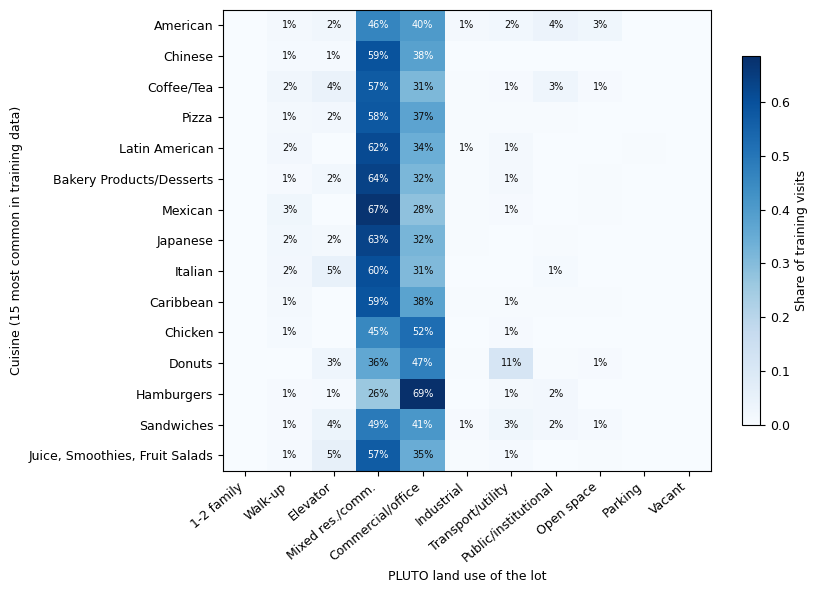

In [10]:
landuse_names = {1: '1-2 family', 2: 'Walk-up', 3: 'Elevator', 4: 'Mixed res./comm.', 5: 'Commercial/office',
                 6: 'Industrial', 7: 'Transport/utility', 8: 'Public/institutional', 9: 'Open space',
                 10: 'Parking', 11: 'Vacant'}

hm = train_merged.assign(lu=pd.to_numeric(train_merged['landuse'], errors='coerce'))
hm = hm[hm['lu'].isin(list(landuse_names)) & hm['cuisine_description'].notna()]
top = hm['cuisine_description'].value_counts().head(15).index
hm = hm[hm['cuisine_description'].isin(top)]
tab = pd.crosstab(hm['cuisine_description'], hm['lu'], normalize='index')
tab = tab.reindex(index=top, columns=[c for c in landuse_names if c in tab.columns], fill_value=0)
tab.rename(columns=landuse_names).to_csv('results/prior_landuse_by_cuisine.csv')

with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 9}):
    fig, ax = plt.subplots(figsize=(8.5, 6))
    vmax = tab.values.max()
    im = ax.imshow(tab.values, cmap='Blues', vmin=0, vmax=vmax, aspect='auto')
    ax.set_xticks(range(tab.shape[1]))
    ax.set_xticklabels([landuse_names[int(c)] for c in tab.columns], rotation=40, ha='right')
    ax.set_yticks(range(tab.shape[0]))
    ax.set_yticklabels(tab.index)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]
            if v >= 0.005:
                ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=7,
                        color='white' if v > 0.55 * vmax else '#0b0b0b')
    ax.set_xlabel('PLUTO land use of the lot')
    ax.set_ylabel('Cuisine (15 most common in training data)')
    cb = fig.colorbar(im, ax=ax, shrink=0.8)
    cb.set_label('Share of training visits')
    fig.tight_layout()
    fig.savefig('paper/fig_prior_heatmap.pdf', bbox_inches='tight')
    fig.savefig('paper/fig_prior_heatmap.png', dpi=200, bbox_inches='tight')
    plt.show()

In [11]:
epsilon_vals = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05]

ref_coords = ref_df[['xcoord', 'ycoord']].values
tree = KDTree(ref_coords)

print('Search radii at 99% coverage:')
for eps in epsilon_vals:
    r = get_search_radius(eps)
    print(f'  eps={eps}: {r:.0f} feet ({r/5280:.2f} miles)')

np.random.seed(42)
releases = {}
for epsilon in epsilon_vals:
    releases[epsilon] = np.column_stack(planar_laplace(test['x'].values, test['y'].values, epsilon))
print('One noisy release per epsilon, shared by every analysis below.')

Search radii at 99% coverage:
  eps=0.001: 6638 feet (1.26 miles)
  eps=0.002: 3319 feet (0.63 miles)
  eps=0.005: 1328 feet (0.25 miles)
  eps=0.01: 664 feet (0.13 miles)
  eps=0.02: 332 feet (0.06 miles)
  eps=0.05: 133 feet (0.03 miles)
One noisy release per epsilon, shared by every analysis below.


## 3. Single-query attack

In [12]:
continuing_camis = set(train_visits['camis'])
test_continuing = test['camis'].isin(continuing_camis).values
test_true = test['bbl'].values
test_cuisine = test['cuisine_description'].values


def evaluate_priors(noisy_coords, epsilon):
    radius = get_search_radius(epsilon, target=0.99)
    n = len(noisy_coords)
    out = {name: (np.zeros(n, dtype=bool), np.full(n, np.nan), np.full(n, np.nan)) for name in priors}
    bound = np.full(n, np.nan)
    disp = np.full(n, np.nan)
    for i in range(n):
        idxs = tree.query_ball_point(noisy_coords[i], r=radius)
        if len(idxs) == 0:
            _, nearest = tree.query(noisy_coords[i], k=1)
            for name in priors:
                out[name][0][i] = lot_bbls[nearest] == test_true[i]
            continue
        idxs = np.asarray(idxs)
        dists = np.linalg.norm(ref_coords[idxs] - noisy_coords[i], axis=1)
        hit = np.flatnonzero(lot_bbls[idxs] == test_true[i])
        t = hit[0] if hit.size else None
        if t is not None:
            disp[i] = dists[t]
            bound[i] = np.exp(epsilon * np.linalg.norm(ref_coords[idxs] - ref_coords[idxs[t]], axis=1).max())
        for name, prior in priors.items():
            correct, post_true, ratio = out[name]
            lw = prior.log_weights(idxs, test_cuisine[i])
            scores = lw - epsilon * dists
            correct[i] = lot_bbls[idxs[np.argmax(scores)]] == test_true[i]
            if t is None:
                continue
            prior_p = np.exp(lw - lw.max())
            post = np.exp(scores - scores.max())
            post_true[i] = post[t] / post.sum()
            ratio[i] = post_true[i] / (prior_p[t] / prior_p.sum())
    return out, bound, disp


def summarize(correct, post_true, ratio, bound, disp, mask):
    ok = mask & ~np.isnan(ratio)
    lo, hi = wilson(int(correct[mask].sum()), int(mask.sum()))
    return {
        'n': int(mask.sum()),
        'reid_rate': correct[mask].mean(),
        'reid_ci_low': lo,
        'reid_ci_high': hi,
        'share_posterior_gt_0_5': (post_true[ok] > 0.5).mean(),
        'median_posterior_true': np.median(post_true[ok]),
        'median_ratio': np.median(ratio[ok]),
        'max_ratio': ratio[ok].max(),
        'bound_satisfied_pct': (ratio[ok] <= bound[ok] * (1 + 1e-9)).mean() * 100,
        'max_ratio_over_bound': (ratio[ok] / bound[ok]).max(),
        'median_bound': np.median(bound[ok]),
        'median_bound_over_ratio': np.median(bound[ok] / ratio[ok]),
        'spearman_rho_disp_ratio': spearmanr(disp[ok], ratio[ok])[0],
    }


prior_rows = []
prior_correct = {}
for epsilon in epsilon_vals:
    results, bound, disp = evaluate_priors(releases[epsilon], epsilon)
    for name, (correct, post_true, ratio) in results.items():
        prior_correct[(epsilon, name)] = correct
        for group, mask in [('all', np.ones(len(test), dtype=bool)),
                            ('continuing', test_continuing), ('new', ~test_continuing)]:
            prior_rows.append({'epsilon': epsilon, 'prior': name, 'group': group,
                               **summarize(correct, post_true, ratio, bound, disp, mask)})
        print(f'eps={epsilon} {name:22s} reid={correct.mean():.4f}')

prior_single = pd.DataFrame(prior_rows)
print(prior_single[prior_single['group'] == 'all']
      .pivot(index='epsilon', columns='prior', values='reid_rate').round(4))

eps=0.001 map_only               reid=0.0062
eps=0.001 building_type          reid=0.0126
eps=0.001 building_type_cuisine  reid=0.0128
eps=0.001 history_any            reid=0.0383
eps=0.001 history_cuisine        reid=0.2421
eps=0.001 everything             reid=0.2424
eps=0.001 control_units          reid=0.0063
eps=0.001 control_year           reid=0.0054
eps=0.002 map_only               reid=0.0164
eps=0.002 building_type          reid=0.0308
eps=0.002 building_type_cuisine  reid=0.0314
eps=0.002 history_any            reid=0.0856
eps=0.002 history_cuisine        reid=0.3670
eps=0.002 everything             reid=0.3667
eps=0.002 control_units          reid=0.0181
eps=0.002 control_year           reid=0.0147
eps=0.005 map_only               reid=0.0640
eps=0.005 building_type          reid=0.0984
eps=0.005 building_type_cuisine  reid=0.1003
eps=0.005 history_any            reid=0.2185
eps=0.005 history_cuisine        reid=0.5503
eps=0.005 everything             reid=0.5515
eps=0.005 

## 4. Multi-record attack (composition evaluation)

In [13]:
test_pos = test.assign(pos=np.arange(len(test)))
restaurants = (test_pos.groupby('camis')
               .agg(true_bbl=('bbl', 'first'), n_obs=('pos', 'size'), cuisine=('cuisine_description', 'first'))
               .reset_index())
restaurants = restaurants[(restaurants['n_obs'] >= 2) & (restaurants['n_obs'] <= 8)].reset_index(drop=True)
restaurants['continuing'] = restaurants['camis'].isin(continuing_camis)
positions_by_camis = test_pos.groupby('camis')['pos'].apply(np.array)
restaurant_positions = [positions_by_camis[c] for c in restaurants['camis']]
n_rest = len(restaurants)
print(f'Restaurants with 2-8 inspections: {n_rest}')

multi_frames = []
for epsilon in epsilon_vals:
    radius = get_search_radius(epsilon, target=0.99)
    noisy = releases[epsilon]
    res = {name: (np.zeros(n_rest, dtype=bool), np.full(n_rest, np.nan), np.full(n_rest, np.nan)) for name in priors}
    bound = np.full(n_rest, np.nan)
    for k, row in enumerate(restaurants.itertuples(index=False)):
        points = noisy[restaurant_positions[k]]
        sets = [set(c) for c in tree.query_ball_point(points, r=radius)]
        cand = set.intersection(*sets) or set.union(*sets)
        if not cand:
            _, nearest = tree.query(points[0], k=1)
            for name in priors:
                res[name][0][k] = lot_bbls[nearest] == row.true_bbl
            continue
        idxs = np.fromiter(cand, dtype=int)
        total_dist = sum(np.linalg.norm(ref_coords[idxs] - p, axis=1) for p in points)
        hit = np.flatnonzero(lot_bbls[idxs] == row.true_bbl)
        t = hit[0] if hit.size else None
        if t is not None:
            bound[k] = np.exp(row.n_obs * epsilon * np.linalg.norm(ref_coords[idxs] - ref_coords[idxs[t]], axis=1).max())
        for name, prior in priors.items():
            correct, post_true, ratio = res[name]
            lw = prior.log_weights(idxs, row.cuisine)
            scores = lw - epsilon * total_dist
            correct[k] = lot_bbls[idxs[np.argmax(scores)]] == row.true_bbl
            if t is None:
                continue
            prior_p = np.exp(lw - lw.max())
            post = np.exp(scores - scores.max())
            post_true[k] = post[t] / post.sum()
            ratio[k] = post_true[k] / (prior_p[t] / prior_p.sum())
    for name, (correct, post_true, ratio) in res.items():
        single = prior_correct[(epsilon, name)]
        multi_frames.append(pd.DataFrame({
            'epsilon': epsilon, 'prior': name, 'restaurant': np.arange(n_rest),
            'n_obs': restaurants['n_obs'].values, 'continuing': restaurants['continuing'].values,
            'hit': correct, 'one_record_avg': [single[p].mean() for p in restaurant_positions],
            'posterior_true': post_true, 'ratio': ratio, 'bound': bound,
        }))
    print(f"eps={epsilon}: all records {res['map_only'][0].mean():.4f} (map_only)")

multi_records = pd.concat(multi_frames, ignore_index=True)

Restaurants with 2-8 inspections: 12650
eps=0.001: all records 0.0085 (map_only)
eps=0.002: all records 0.0207 (map_only)
eps=0.005: all records 0.0951 (map_only)
eps=0.01: all records 0.2363 (map_only)
eps=0.02: all records 0.4596 (map_only)
eps=0.05: all records 0.7538 (map_only)


In [14]:
np.random.seed(2026)
exact_frames = []
for epsilon in epsilon_vals:
    for n_obs in sorted(restaurants['n_obs'].unique()):
        sel = np.flatnonzero(restaurants['n_obs'].values == n_obs)
        pos = np.concatenate([restaurant_positions[k] for k in sel])
        owner = np.concatenate([np.full(len(restaurant_positions[k]), k) for k in sel])
        eps_n = n_obs * epsilon
        radius = get_search_radius(eps_n, target=0.99)
        noisy_n = np.column_stack(planar_laplace(test['x'].values[pos], test['y'].values[pos], eps_n))
        hits = {name: np.zeros(len(pos), dtype=bool) for name in priors}
        for j, point in enumerate(noisy_n):
            truth = test_true[pos[j]]
            idxs = tree.query_ball_point(point, r=radius)
            if len(idxs) == 0:
                _, nearest = tree.query(point, k=1)
                for name in priors:
                    hits[name][j] = lot_bbls[nearest] == truth
                continue
            idxs = np.asarray(idxs)
            dists = np.linalg.norm(ref_coords[idxs] - point, axis=1)
            for name, prior in priors.items():
                scores = prior.log_weights(idxs, test_cuisine[pos[j]]) - eps_n * dists
                hits[name][j] = lot_bbls[idxs[np.argmax(scores)]] == truth
        for name in priors:
            per_restaurant = pd.Series(hits[name]).groupby(owner).mean()
            exact_frames.append(pd.DataFrame({'epsilon': epsilon, 'prior': name,
                                              'restaurant': per_restaurant.index.values,
                                              'single_at_n_eps': per_restaurant.values}))
    print(f'eps={epsilon} done')

multi_records = multi_records.merge(pd.concat(exact_frames, ignore_index=True),
                                    on=['epsilon', 'prior', 'restaurant'], how='left')

eps=0.001 done
eps=0.002 done
eps=0.005 done
eps=0.01 done
eps=0.02 done
eps=0.05 done


In [15]:
multi_records['n_bucket'] = np.where(multi_records['n_obs'] <= 4, multi_records['n_obs'].astype(str), '5-8')


def summarize_multi(g):
    ok = g['ratio'].notna()
    lo, hi = wilson(int(g['hit'].sum()), len(g))
    lo1, hi1 = mean_ci(g['one_record_avg'])
    lo2, hi2 = mean_ci(g['single_at_n_eps'])
    return pd.Series({
        'n_restaurants': len(g),
        'reid_one_record_avg': g['one_record_avg'].mean(), 'one_record_ci_low': lo1, 'one_record_ci_high': hi1,
        'reid_rate': g['hit'].mean(), 'reid_ci_low': lo, 'reid_ci_high': hi,
        'linking_gain': g['hit'].mean() - g['one_record_avg'].mean(),
        'reid_single_at_n_eps': g['single_at_n_eps'].mean(), 'single_at_n_eps_ci_low': lo2, 'single_at_n_eps_ci_high': hi2,
        'median_posterior_true': g.loc[ok, 'posterior_true'].median(),
        'median_ratio': g.loc[ok, 'ratio'].median(),
        'max_ratio': g.loc[ok, 'ratio'].max(),
        'bound_satisfied_pct': (g.loc[ok, 'ratio'] <= g.loc[ok, 'bound'] * (1 + 1e-9)).mean() * 100,
        'max_ratio_over_bound': (g.loc[ok, 'ratio'] / g.loc[ok, 'bound']).max(),
        'median_bound_over_ratio': (g.loc[ok, 'bound'] / g.loc[ok, 'ratio']).median(),
    })


multi_parts = []
for group, mask in [('all', np.ones(len(multi_records), dtype=bool)),
                    ('continuing', multi_records['continuing'].values),
                    ('new', ~multi_records['continuing'].values)]:
    for key in ['n_obs', 'n_bucket']:
        part = (multi_records[mask].groupby(['epsilon', 'prior', key])
                .apply(summarize_multi).reset_index().rename(columns={key: 'n_linked'}))
        part['n_linked'] = part['n_linked'].astype(str)
        multi_parts.append(part.assign(grouping=key, group=group))
prior_multi = pd.concat(multi_parts, ignore_index=True)

show = ['epsilon', 'n_linked', 'n_restaurants', 'reid_one_record_avg', 'reid_rate', 'linking_gain', 'reid_single_at_n_eps']
for name in ['map_only', 'building_type', 'history_cuisine']:
    print(f'\n=== {name}: same restaurants, one record (average) vs all linked records vs one release at n*eps ===')
    sub = prior_multi[(prior_multi['prior'] == name) & (prior_multi['group'] == 'all') & (prior_multi['grouping'] == 'n_bucket')]
    print(sub[show].round(4).to_string(index=False))

bound_rows = prior_multi[(prior_multi['group'] == 'all') & (prior_multi['grouping'] == 'n_obs')]
print('\nMulti-record bound check (ratio <= exp(n * eps * D)):')
print(f"  lowest share of restaurants within the bound: {bound_rows['bound_satisfied_pct'].min():.4f}%")
print(f"  largest ratio / bound: {bound_rows['max_ratio_over_bound'].max():.12g}")
print(bound_rows.pivot_table(index='epsilon', columns='prior', values='median_bound_over_ratio', aggfunc='median').round(0).to_string())


=== map_only: same restaurants, one record (average) vs all linked records vs one release at n*eps ===
 epsilon n_linked  n_restaurants  reid_one_record_avg  reid_rate  linking_gain  reid_single_at_n_eps
   0.001        2         8285.0               0.0072     0.0065       -0.0007                0.0171
   0.001        3         2797.0               0.0050     0.0100        0.0050                0.0278
   0.001        4          972.0               0.0036     0.0144        0.0108                0.0376
   0.001      5-8          596.0               0.0048     0.0185        0.0137                0.0638
   0.002        2         8285.0               0.0177     0.0192        0.0014                0.0473
   0.002        3         2797.0               0.0132     0.0240        0.0107                0.0796
   0.002        4          972.0               0.0118     0.0185        0.0067                0.1121
   0.002      5-8          596.0               0.0135     0.0302        0.0167          

## 5. Utility evaluation

In [16]:
# Download from: https://data.cityofnewyork.us/City-Government/2020-Census-Tracts/63ge-mke6

tracts = gpd.read_file(TRACTS_PATH)
if tracts.crs != 'EPSG:2263':
    tracts = tracts.to_crs('EPSG:2263')
print(f'Tracts: {len(tracts)}')

Tracts: 2325


In [17]:
def tract_of(x, y):
    points = gpd.GeoDataFrame(geometry=gpd.points_from_xy(x, y), crs='EPSG:2263')
    joined = gpd.sjoin(points, tracts[['geometry']], how='left', predicate='within')
    joined = joined[~joined.index.duplicated(keep='first')].sort_index()
    return joined['index_right'].values


def weighted_median(values, weights):
    order = np.argsort(values)
    cum = np.cumsum(weights[order])
    return values[order][np.searchsorted(cum, cum[-1] / 2)]


true_tract = tract_of(test['x'].values, test['y'].values)
score_rows, cuisine_rows, coverage_rows = [], [], []

for epsilon, noisy_xy in releases.items():
    rec = pd.DataFrame({'true_tract': true_tract, 'noisy_tract': tract_of(noisy_xy[:, 0], noisy_xy[:, 1]),
                        'score': test['score'].values, 'cuisine': test['cuisine_description'].values})

    true_counts = rec.dropna(subset=['true_tract']).groupby('true_tract').size()
    noisy_counts = rec.dropna(subset=['noisy_tract']).groupby('noisy_tract').size()
    lost = ~true_counts.index.isin(noisy_counts.index)
    coverage_rows.append({
        'epsilon': epsilon,
        'tracts_with_restaurants': len(true_counts),
        'share_tracts_lost': lost.mean(),
        'share_records_in_lost_tracts': true_counts[lost].sum() / true_counts.sum(),
        'tracts_gained': int((~noisy_counts.index.isin(true_counts.index)).sum()),
        'share_records_pushed_outside_tracts': (rec['noisy_tract'].isna() & rec['true_tract'].notna()).sum() / rec['true_tract'].notna().sum(),
    })

    s = rec[rec['score'].notna()]
    true_s = s.dropna(subset=['true_tract']).groupby('true_tract')['score'].agg(['mean', 'size'])
    noisy_s = s.dropna(subset=['noisy_tract']).groupby('noisy_tract')['score'].agg(['mean', 'size'])
    both = true_s.index.intersection(noisy_s.index)
    w = true_s.loc[both, 'size'].values
    err = true_s.loc[both, 'mean'].values - noisy_s.loc[both, 'mean'].values
    score_rows.append({'epsilon': epsilon,
                       'rmse': np.sqrt(np.sum(w * err ** 2) / w.sum()),
                       'mae': np.sum(w * np.abs(err)) / w.sum(),
                       'tracts_compared': len(both)})

    c = rec.dropna(subset=['cuisine'])
    true_c = c.dropna(subset=['true_tract']).groupby(['true_tract', 'cuisine']).size().unstack(fill_value=0)
    noisy_c = c.dropna(subset=['noisy_tract']).groupby(['noisy_tract', 'cuisine']).size().unstack(fill_value=0)
    both_c = true_c.index.intersection(noisy_c.index)
    cols = true_c.columns.union(noisy_c.columns)
    tc = true_c.reindex(index=both_c, columns=cols, fill_value=0)
    nc = noisy_c.reindex(index=both_c, columns=cols, fill_value=0)
    tvd = 0.5 * (tc.div(tc.sum(axis=1), axis=0) - nc.div(nc.sum(axis=1), axis=0)).abs().sum(axis=1).values
    wc = tc.sum(axis=1).values
    cuisine_rows.append({'epsilon': epsilon,
                         'tvd_mean': np.sum(wc * tvd) / wc.sum(),
                         'tvd_median': weighted_median(tvd, wc),
                         'tracts_compared': len(both_c)})

utility_score_df = pd.DataFrame(score_rows)
utility_cuisine_df = pd.DataFrame(cuisine_rows)
utility_coverage_df = pd.DataFrame(coverage_rows)

print('Inspection score distortion (tracts with restaurants before and after noise, weighted by records)')
print(utility_score_df.round(4).to_string(index=False))
print('\nCuisine composition distortion (same tracts, weighted by records)')
print(utility_cuisine_df.round(4).to_string(index=False))
print('\nTract coverage')
print(utility_coverage_df.round(4).to_string(index=False))

Inspection score distortion (tracts with restaurants before and after noise, weighted by records)
 epsilon   rmse    mae  tracts_compared
   0.001 4.5487 3.1552             1943
   0.002 4.0228 2.6876             1935
   0.005 3.0841 1.8741             1927
   0.010 2.4234 1.3208             1929
   0.020 1.5686 0.8253             1940
   0.050 0.7001 0.2012             1945

Cuisine composition distortion (same tracts, weighted by records)
 epsilon  tvd_mean  tvd_median  tracts_compared
   0.001    0.4455      0.4179             1949
   0.002    0.3556      0.3283             1940
   0.005    0.2309      0.2028             1932
   0.010    0.1491      0.1230             1934
   0.020    0.0781      0.0595             1944
   0.050    0.0167      0.0068             1950

Tract coverage
 epsilon  tracts_with_restaurants  share_tracts_lost  share_records_in_lost_tracts  tracts_gained  share_records_pushed_outside_tracts
   0.001                     1952             0.0015                

In [18]:
true_ids = np.where(pd.isna(true_tract), -1, true_tract).astype(int)
tract_area_acres = tracts.geometry.area / 43560
tract_boro = pd.Series(test['boro'].values)[true_ids >= 0].groupby(true_ids[true_ids >= 0]).agg(lambda s: s.mode().iloc[0])

tract_frames = []
for epsilon, noisy_xy in releases.items():
    noisy = tract_of(noisy_xy[:, 0], noisy_xy[:, 1])
    rec = pd.DataFrame({'true_tract': true_ids, 'noisy_tract': np.where(pd.isna(noisy), -1, noisy).astype(int),
                        'score': test['score'].values, 'cuisine': test['cuisine_description'].values})
    rec = rec[rec['true_tract'] >= 0]

    cz = rec.dropna(subset=['cuisine'])
    nz = cz[cz['noisy_tract'] >= 0]
    true_mix = pd.crosstab(cz['true_tract'], cz['cuisine'], normalize='index')
    noisy_mix = pd.crosstab(nz['noisy_tract'], nz['cuisine'], normalize='index')
    idx = true_mix.index.intersection(noisy_mix.index)
    cols = true_mix.columns.union(noisy_mix.columns)
    tvd = 0.5 * (true_mix.reindex(index=idx, columns=cols, fill_value=0)
                 - noisy_mix.reindex(index=idx, columns=cols, fill_value=0)).abs().sum(axis=1)

    sc = rec.dropna(subset=['score'])
    true_mean = sc.groupby('true_tract')['score'].mean()
    noisy_mean = sc[sc['noisy_tract'] >= 0].groupby('noisy_tract')['score'].mean()

    tract = pd.DataFrame({'records': rec.groupby('true_tract').size()})
    tract['tvd'] = tvd
    tract['abs_score_error'] = (true_mean - noisy_mean).abs()
    tract['area_acres'] = tract_area_acres.reindex(tract.index).values
    tract['borough'] = tract_boro.reindex(tract.index).values
    tract_frames.append(tract.assign(epsilon=epsilon))

tract_util = pd.concat(tract_frames).rename_axis('tract').reset_index()

area_edges = np.quantile(tract_util.loc[tract_util['epsilon'] == epsilon_vals[0], 'area_acres'], [0, .25, .5, .75, 1])
area_labels = [f'{area_edges[i]:.0f}-{area_edges[i + 1]:.0f} acres' for i in range(4)]
tract_util['area_band'] = pd.cut(tract_util['area_acres'], bins=area_edges, labels=area_labels, include_lowest=True)
records_labels = ['1-2', '3-5', '6-15', '16+']
tract_util['records_band'] = pd.cut(tract_util['records'], bins=[0, 2, 5, 15, np.inf], labels=records_labels)


def wmean(g, col):
    ok = g[col].notna()
    return np.average(g.loc[ok, col], weights=g.loc[ok, 'records']) if ok.any() else np.nan


metrics = {'tvd': 'cuisine TVD', 'abs_score_error': 'absolute score error'}
boroughs_u = sorted(tract_util['borough'].dropna().unique())

boro_rows = []
for (epsilon, borough), g in tract_util.groupby(['epsilon', 'borough']):
    boro_rows.append({'epsilon': epsilon, 'borough': borough, **{m: wmean(g, m) for m in metrics}})
boro_util = pd.DataFrame(boro_rows)
for m, label in metrics.items():
    print(f'\n=== Utility loss by borough: {label} (weighted by records) ===')
    print(boro_util.pivot(index='epsilon', columns='borough', values=m).round(3).to_string())

std_rows, band_rows = [], []
for band_col, labels in [('area_band', area_labels), ('records_band', records_labels)]:
    for epsilon, g in tract_util.groupby('epsilon'):
        city_mix_u = g.groupby(band_col, observed=False)['records'].sum().reindex(labels)
        city_mix_u = city_mix_u / city_mix_u.sum()
        for m in metrics:
            by_band = {b: wmean(gb, m) for b, gb in g.groupby(band_col, observed=False)}
            band_rows.append({'characteristic': band_col, 'epsilon': epsilon, 'metric': m, **by_band})
            for borough in boroughs_u:
                gbor = g[g['borough'] == borough]
                rates_u = pd.Series({b: wmean(gb, m) for b, gb in gbor.groupby(band_col, observed=False)}).reindex(labels)
                std_rows.append({'characteristic': band_col, 'epsilon': epsilon, 'metric': m, 'borough': borough,
                                 'actual': wmean(gbor, m),
                                 'at_citywide_mix': (rates_u * city_mix_u).sum(min_count=len(labels))})

band_util = pd.DataFrame(band_rows)
std_util = pd.DataFrame(std_rows)

for band_col, labels in [('area_band', area_labels), ('records_band', records_labels)]:
    for m, label in metrics.items():
        print(f'\n=== {label} by {band_col.replace("_band", "")} band, all boroughs ===')
        print(band_util[(band_util['characteristic'] == band_col) & (band_util['metric'] == m)]
              .set_index('epsilon')[labels].round(3).to_string())

spread_u = std_util.groupby(['characteristic', 'metric', 'epsilon']).agg(
    spread_actual=('actual', lambda s: s.max() - s.min()),
    spread_at_citywide_mix=('at_citywide_mix', lambda s: s.max() - s.min()),
).reset_index()
spread_u['share_of_spread_removed'] = 1 - spread_u['spread_at_citywide_mix'] / spread_u['spread_actual']
for band_col in ['area_band', 'records_band']:
    for m, label in metrics.items():
        print(f'\n=== Borough spread in {label}, evening out {band_col.replace("_band", "")} ===')
        print(spread_u[(spread_u['characteristic'] == band_col) & (spread_u['metric'] == m)]
              .set_index('epsilon')[['spread_actual', 'spread_at_citywide_mix', 'share_of_spread_removed']].round(3).to_string())

print('\nTracts per band (tracts with restaurants)')
first = tract_util[tract_util['epsilon'] == epsilon_vals[0]]
print(pd.crosstab(first['borough'], first['area_band']).to_string())
print(pd.crosstab(first['borough'], first['records_band']).to_string())


=== Utility loss by borough: cuisine TVD (weighted by records) ===
borough  Bronx  Brooklyn  Manhattan  Queens  Staten Island
epsilon                                                   
0.001    0.522     0.516      0.371   0.461          0.412
0.002    0.432     0.407      0.300   0.364          0.317
0.005    0.270     0.260      0.195   0.239          0.237
0.010    0.176     0.174      0.120   0.159          0.137
0.020    0.101     0.092      0.057   0.085          0.088
0.050    0.017     0.021      0.012   0.019          0.009

=== Utility loss by borough: absolute score error (weighted by records) ===
borough  Bronx  Brooklyn  Manhattan  Queens  Staten Island
epsilon                                                   
0.001    3.799     3.796      2.216   3.783          2.320
0.002    3.425     3.398      1.867   3.033          2.022
0.005    2.271     2.397      1.185   2.256          1.703
0.010    1.774     1.746      0.797   1.538          1.094
0.020    0.956     1.123     

In [19]:
tract_geo = tracts[['geometry']].copy()
tract_geo['tract'] = tract_geo.index
touch = gpd.sjoin(tract_geo, tract_geo, how='inner', predicate='touches')
touch = touch.loc[touch['tract_left'] != touch['tract_right'], ['tract_left', 'tract_right']]

recs = pd.DataFrame({'tract': true_ids, 'score': test['score'].values, 'cuisine': test['cuisine_description'].values})
recs = recs[recs['tract'] >= 0]


def pool_over_neighbors(table):
    pooled = table.reindex(touch['tract_right'].values).fillna(0)
    pooled.index = touch['tract_left'].values
    return pooled.groupby(level=0).sum()


cuisine_counts = pd.crosstab(recs['tract'], recs['cuisine'])
own_mix = cuisine_counts.div(cuisine_counts.sum(axis=1), axis=0)
nb_counts = pool_over_neighbors(cuisine_counts).reindex(index=own_mix.index, columns=own_mix.columns).fillna(0)
nb_total = nb_counts.sum(axis=1)
nb_mix = nb_counts.div(nb_total.where(nb_total > 0), axis=0)
neighbor_cuisine_gap = 0.5 * (own_mix - nb_mix).abs().sum(axis=1).where(nb_total > 0)

score_sum = recs.dropna(subset=['score']).groupby('tract')['score'].agg(['sum', 'count'])
nb_score = pool_over_neighbors(score_sum)
own_mean = score_sum['sum'] / score_sum['count']
nb_mean = (nb_score['sum'] / nb_score['count'].where(nb_score['count'] > 0)).reindex(own_mean.index)
neighbor_score_gap = (own_mean - nb_mean).abs()

tract_util['neighbor_cuisine_gap'] = tract_util['tract'].map(neighbor_cuisine_gap)
tract_util['neighbor_score_gap'] = tract_util['tract'].map(neighbor_score_gap)


def make_bands(col, fmt):
    base = tract_util.loc[tract_util['epsilon'] == epsilon_vals[0], col].dropna()
    edges = np.unique(np.quantile(base, [0, .25, .5, .75, 1]))
    labels = [f'{fmt(edges[i])}-{fmt(edges[i + 1])}' for i in range(len(edges) - 1)]
    tract_util[col + '_band'] = pd.cut(tract_util[col], bins=edges, labels=labels, include_lowest=True)
    return labels


cuisine_gap_labels = make_bands('neighbor_cuisine_gap', lambda v: f'{v:.2f}')
score_gap_labels = make_bands('neighbor_score_gap', lambda v: f'{v:.1f}')
pairs = [('tvd', 'neighbor_cuisine_gap_band', cuisine_gap_labels, 'cuisine TVD', 'cuisine-mix gap to neighbors'),
         ('abs_score_error', 'neighbor_score_gap_band', score_gap_labels, 'absolute score error', 'mean-score gap to neighbors')]

first = tract_util[tract_util['epsilon'] == epsilon_vals[0]]
print('How different each tract is from its neighbors, by borough (weighted by records)')
print(pd.DataFrame({'cuisine_mix_gap': first.groupby('borough').apply(lambda g: wmean(g, 'neighbor_cuisine_gap')),
                    'mean_score_gap': first.groupby('borough').apply(lambda g: wmean(g, 'neighbor_score_gap'))}).round(3).to_string())

nb_std_rows = []
for m, band_col, labels, label, gap_label in pairs:
    print(f'\n=== {label} by {gap_label} band, all boroughs ===')
    print(tract_util.groupby(['epsilon', band_col], observed=False)
          .apply(lambda g: wmean(g, m)).unstack(band_col)[labels].round(3).to_string())
    print(f'\nMedian records per tract in each {gap_label} band')
    print(first.groupby(band_col, observed=False)['records'].median()[labels].to_string())
    for epsilon, g in tract_util.groupby('epsilon'):
        mix = g.groupby(band_col, observed=False)['records'].sum().reindex(labels)
        mix = mix / mix.sum()
        for borough in boroughs_u:
            gb = g[g['borough'] == borough]
            rates_nb = pd.Series({b: wmean(x, m) for b, x in gb.groupby(band_col, observed=False)}).reindex(labels)
            nb_std_rows.append({'metric': m, 'epsilon': epsilon, 'borough': borough, 'actual': wmean(gb, m),
                                'at_citywide_mix': (rates_nb * mix).sum(min_count=len(labels))})

nb_std = pd.DataFrame(nb_std_rows)
nb_spread = nb_std.groupby(['metric', 'epsilon']).agg(
    spread_actual=('actual', lambda s: s.max() - s.min()),
    spread_at_citywide_mix=('at_citywide_mix', lambda s: s.max() - s.min()),
).reset_index()
nb_spread['share_of_spread_removed'] = 1 - nb_spread['spread_at_citywide_mix'] / nb_spread['spread_actual']
for m, band_col, labels, label, gap_label in pairs:
    print(f'\n=== Borough spread in {label}, evening out {gap_label} ===')
    print(nb_spread[nb_spread['metric'] == m].set_index('epsilon')
          [['spread_actual', 'spread_at_citywide_mix', 'share_of_spread_removed']].round(3).to_string())
    print(f'\n{label} by borough at the citywide {gap_label} mix')
    print(nb_std[nb_std['metric'] == m].pivot(index='epsilon', columns='borough', values='at_citywide_mix').round(3).to_string())

How different each tract is from its neighbors, by borough (weighted by records)
               cuisine_mix_gap  mean_score_gap
borough                                       
Bronx                    0.614           3.227
Brooklyn                 0.563           3.325
Manhattan                0.397           1.893
Queens                   0.541           3.339
Staten Island            0.563           2.867

=== cuisine TVD by cuisine-mix gap to neighbors band, all boroughs ===
neighbor_cuisine_gap_band  0.14-0.51  0.51-0.65  0.65-0.80  0.80-1.00
epsilon                                                              
0.001                          0.356      0.494      0.589      0.759
0.002                          0.280      0.396      0.478      0.628
0.005                          0.181      0.258      0.311      0.411
0.010                          0.113      0.168      0.206      0.279
0.020                          0.058      0.091      0.109      0.137
0.050                       

## 6. Density stratification (borough)

In [20]:
boroughs = ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']
test_boro = test['boro'].values
borough_rows = []
for (epsilon, name), correct in prior_correct.items():
    for borough in boroughs:
        mask = test_boro == borough
        borough_rows.append({'prior': name, 'epsilon': epsilon, 'borough': borough,
                             'reid_rate': correct[mask].mean(), 'n_records': int(mask.sum())})
borough_df = pd.DataFrame(borough_rows)

for name in ['map_only', 'building_type', 'history_cuisine']:
    print(f'\n=== {name} ===')
    print(borough_df[borough_df['prior'] == name]
          .pivot(index='epsilon', columns='borough', values='reid_rate').round(4))

print('\nTest records per borough:')
print(test['boro'].value_counts())


=== map_only ===
borough   Bronx  Brooklyn  Manhattan  Queens  Staten Island
epsilon                                                    
0.001    0.0098    0.0036     0.0046  0.0099         0.0084
0.002    0.0261    0.0100     0.0139  0.0207         0.0359
0.005    0.0910    0.0416     0.0635  0.0679         0.1378
0.010    0.2157    0.1125     0.1614  0.1636         0.2855
0.020    0.4170    0.2548     0.3464  0.3376         0.4810
0.050    0.7472    0.5351     0.6598  0.6324         0.7841

=== building_type ===
borough   Bronx  Brooklyn  Manhattan  Queens  Staten Island
epsilon                                                    
0.001    0.0217    0.0068     0.0055  0.0228         0.0387
0.002    0.0497    0.0210     0.0149  0.0494         0.0970
0.005    0.1588    0.0762     0.0629  0.1322         0.2539
0.010    0.3123    0.1766     0.1729  0.2537         0.4184
0.020    0.5368    0.3440     0.3676  0.4391         0.6139
0.050    0.8081    0.6024     0.6709  0.6905         0.8298

In [21]:
radius_01 = get_search_radius(0.01, target=0.99)
candidates, share_mc = [], []
for point in test[['x', 'y']].values:
    c = tree.query_ball_point(point, r=radius_01)
    candidates.append(len(c))
    share_mc.append(np.isin(lu_code[c], [4, 5]).mean() if len(c) else np.nan)
borough_frame = pd.DataFrame({
    'borough': test['boro'].values,
    'candidates': candidates,
    'share_mixed_or_commercial': share_mc,
})
true_lot = bbl_to_lot.loc[test['bbl'].values].values
nn_dist, _ = tree.query(ref_coords[true_lot], k=2)
borough_frame['nearest_other_lot_ft'] = nn_dist[:, 1]
borough_frame['lots_within_100ft'] = tree.query_ball_point(ref_coords[true_lot], r=100, return_length=True) - 1
for name in priors:
    borough_frame[f'reid_{name}'] = prior_correct[(0.01, name)]
borough_summary = borough_frame.groupby('borough').agg(
    records=('candidates', 'size'),
    median_candidates=('candidates', 'median'),
    mean_share_mixed_or_commercial=('share_mixed_or_commercial', 'mean'),
    median_nearest_other_lot_ft=('nearest_other_lot_ft', 'median'),
    median_lots_within_100ft=('lots_within_100ft', 'median'),
    **{f'reid_{name}': (f'reid_{name}', 'mean') for name in priors},
).reset_index()
print(borough_summary.round(3).to_string(index=False))

      borough  records  median_candidates  mean_share_mixed_or_commercial  median_nearest_other_lot_ft  median_lots_within_100ft  reid_map_only  reid_building_type  reid_building_type_cuisine  reid_history_any  reid_history_cuisine  reid_everything  reid_control_units  reid_control_year
        Bronx     4288              137.0                           0.244                       67.179                       2.0          0.216               0.312                       0.318             0.519                 0.773            0.785               0.230              0.218
     Brooklyn    11440              281.0                           0.250                       25.495                       6.0          0.112               0.177                       0.178             0.371                 0.684            0.689               0.109              0.109
    Manhattan    16873              137.0                           0.580                       48.847                       3.0        

In [22]:
spacing_labels = ['<25 ft', '25-50 ft', '50-100 ft', '100+ ft']
borough_frame['spacing_bin'] = pd.cut(borough_frame['nearest_other_lot_ft'], bins=[0, 25, 50, 100, np.inf],
                                      labels=spacing_labels, right=False)

city_mix = borough_frame['spacing_bin'].value_counts(normalize=True).reindex(spacing_labels)

spacing_bin_values = borough_frame['spacing_bin'].values
borough_values = borough_frame['borough'].values

cell_frames, std_frames = [], []
for (epsilon, name), correct in prior_correct.items():
    df = pd.DataFrame({'borough': borough_values, 'spacing_bin': spacing_bin_values, 'hit': correct})
    cells = (df.groupby(['borough', 'spacing_bin'], observed=False)['hit']
               .agg(records='size', reid_rate='mean').reset_index())
    cell_frames.append(cells.assign(epsilon=epsilon, prior=name))
    rates = cells.pivot(index='borough', columns='spacing_bin', values='reid_rate')[spacing_labels]
    actual = df.groupby('borough')['hit'].mean()
    standardized = (rates * city_mix).sum(axis=1, min_count=len(spacing_labels)).reindex(actual.index)
    std_frames.append(pd.DataFrame({'epsilon': epsilon, 'prior': name, 'borough': actual.index,
                                    'actual': actual.values, 'at_citywide_spacing_mix': standardized.values}))

spacing_cells = pd.concat(cell_frames, ignore_index=True)
spacing_std = pd.concat(std_frames, ignore_index=True)

spread_all = spacing_std.groupby(['epsilon', 'prior']).agg(
    spread_actual=('actual', lambda s: s.max() - s.min()),
    spread_at_citywide_mix=('at_citywide_spacing_mix', lambda s: s.max() - s.min()),
).reset_index()
spread_all['share_of_spread_removed'] = 1 - spread_all['spread_at_citywide_mix'] / spread_all['spread_actual']

city_by_bin = (spacing_cells.assign(hits=spacing_cells['records'] * spacing_cells['reid_rate'])
               .groupby(['epsilon', 'prior', 'spacing_bin'], observed=False)[['hits', 'records']].sum())
city_by_bin['reid_rate'] = city_by_bin['hits'] / city_by_bin['records']
city_by_bin = city_by_bin.reset_index()

order = list(priors)
for epsilon in epsilon_vals:
    print(f'\n=== eps={epsilon}: re-identification by nearest-lot spacing, all boroughs ===')
    print(city_by_bin[city_by_bin['epsilon'] == epsilon]
          .pivot(index='spacing_bin', columns='prior', values='reid_rate')[order].round(3).to_string())

for col, title in [('spread_actual', 'Borough spread (highest minus lowest), actual'),
                   ('spread_at_citywide_mix', 'Borough spread at the citywide spacing mix'),
                   ('share_of_spread_removed', 'Share of borough spread removed by evening out spacing')]:
    print(f'\n=== {title} ===')
    print(spread_all.pivot(index='epsilon', columns='prior', values=col)[order].round(3).to_string())


=== eps=0.001: re-identification by nearest-lot spacing, all boroughs ===
prior        map_only  building_type  building_type_cuisine  history_any  history_cuisine  everything  control_units  control_year
spacing_bin                                                                                                                       
<25 ft          0.001          0.001                  0.001        0.023            0.221       0.221          0.000         0.001
25-50 ft        0.001          0.004                  0.004        0.020            0.208       0.208          0.001         0.001
50-100 ft       0.003          0.014                  0.014        0.038            0.257       0.257          0.006         0.004
100+ ft         0.025          0.038                  0.040        0.086            0.300       0.302          0.023         0.020

=== eps=0.002: re-identification by nearest-lot spacing, all boroughs ===
prior        map_only  building_type  building_type_cuisine  his

## 7. Posterior analysis

In [23]:
cols = ['median_posterior_true', 'median_ratio', 'max_ratio', 'share_posterior_gt_0_5',
        'bound_satisfied_pct', 'max_ratio_over_bound', 'median_bound', 'median_bound_over_ratio',
        'spearman_rho_disp_ratio']
print('=== POSTERIOR SUMMARY (all records) ===')
print(prior_single[prior_single['group'] == 'all'].set_index(['prior', 'epsilon'])[cols].to_string(float_format=lambda v: f'{v:.6g}'))
print('\nBound satisfied for every record under every prior:', bool((prior_single['bound_satisfied_pct'] == 100).all()))

=== POSTERIOR SUMMARY (all records) ===
                               median_posterior_true  median_ratio  max_ratio  share_posterior_gt_0_5  bound_satisfied_pct  max_ratio_over_bound  median_bound  median_bound_over_ratio  spearman_rho_disp_ratio
prior                 epsilon                                                                                                                                                                                   
map_only              0.001              0.000304773       3.77276    163.679             0.000604906                  100                     1        3536.8                  932.774                -0.944435
building_type         0.001               0.00127911         3.416    139.986             0.000604906                  100                     1        3536.8                  1017.63                -0.909792
building_type_cuisine 0.001               0.00130288       3.41399    228.773             0.000649714                  100  

## 8. Visualization

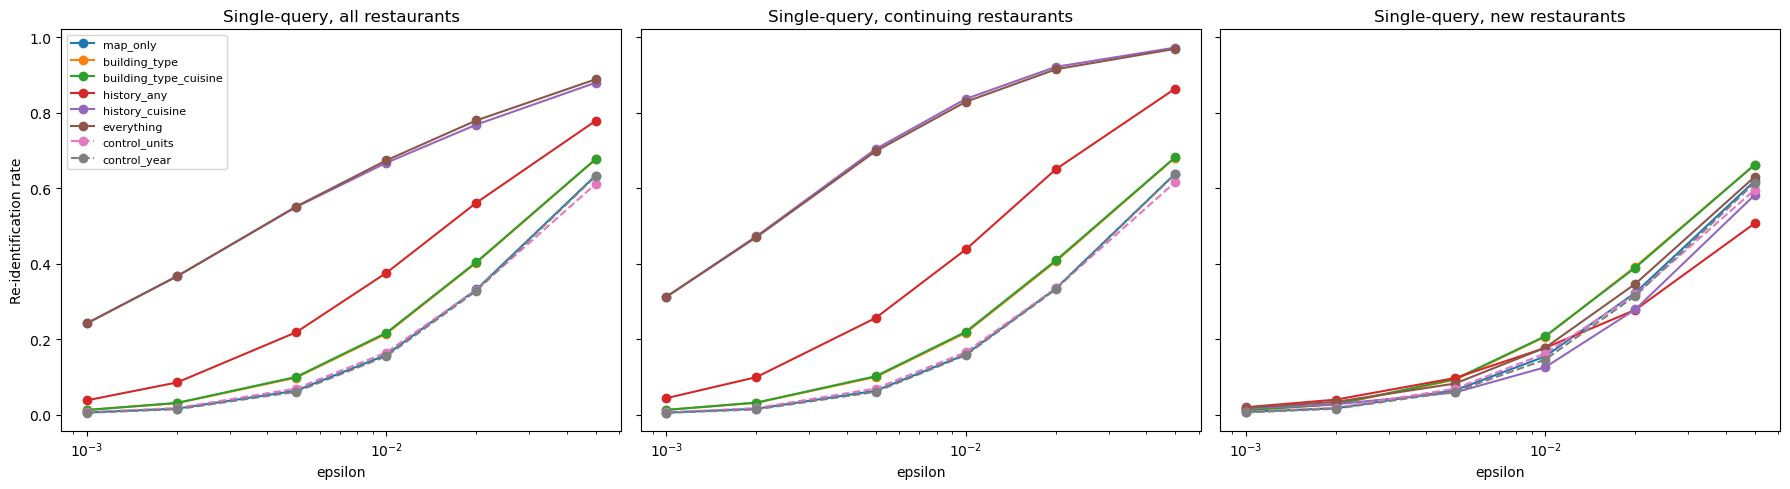

In [24]:
main_priors = ['map_only', 'building_type', 'building_type_cuisine', 'history_any', 'history_cuisine', 'everything']
single_all = prior_single[prior_single['group'] == 'all']

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, group in zip(axes, ['all', 'continuing', 'new']):
    sub = prior_single[prior_single['group'] == group]
    for name in priors:
        s = sub[sub['prior'] == name].sort_values('epsilon')
        ax.plot(s['epsilon'], s['reid_rate'], marker='o', label=name,
                linestyle='--' if name.startswith('control') else '-')
    ax.set_xscale('log')
    ax.set_xlabel('epsilon')
    ax.set_title(f'Single-query, {group} restaurants')
axes[0].set_ylabel('Re-identification rate')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

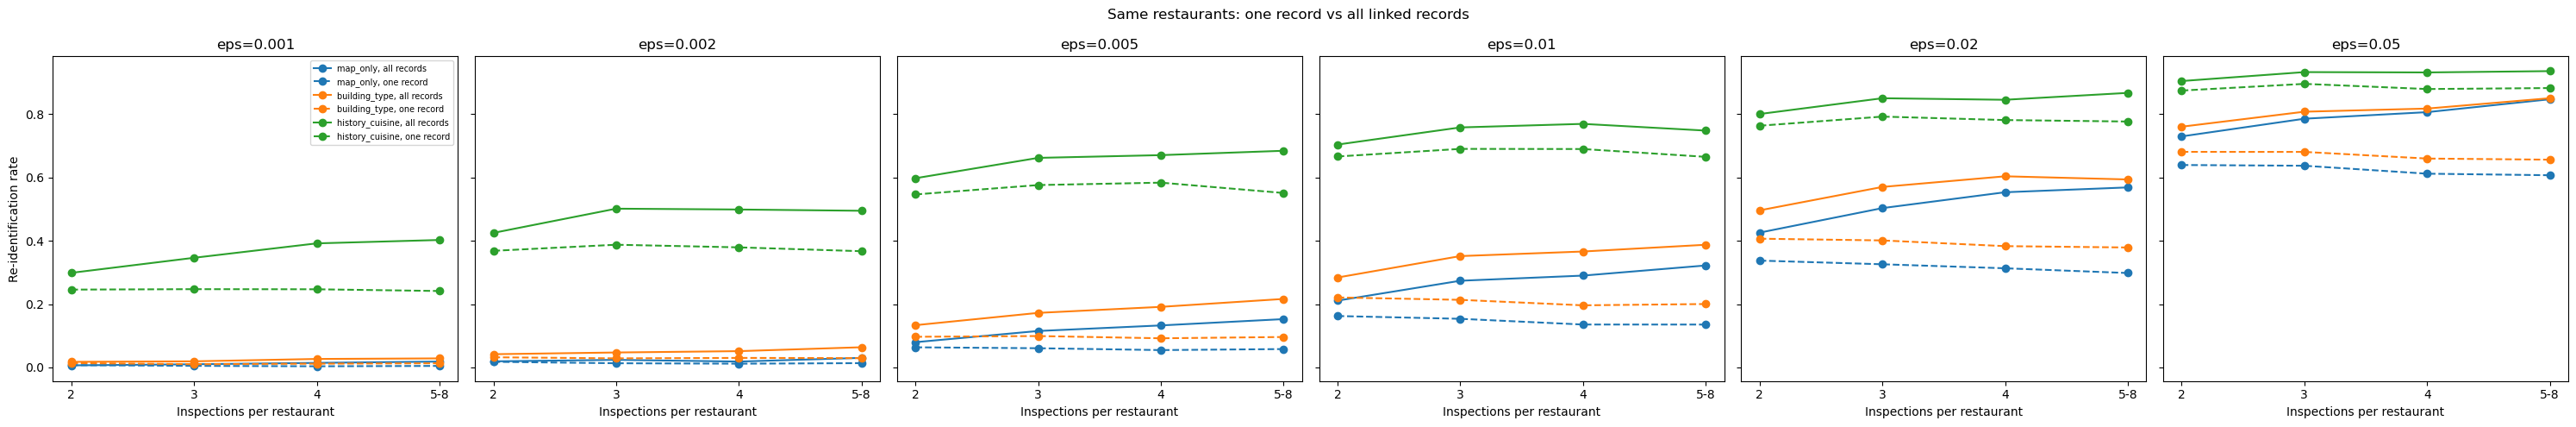


=== Restaurants per bucket ===
n_linked  n_restaurants
       2         8285.0
       3         2797.0
       4          972.0
     5-8          596.0


In [25]:
bucket_order = ['2', '3', '4', '5-8']
vis_multi = prior_multi[(prior_multi['group'] == 'all') & (prior_multi['grouping'] == 'n_bucket')]

fig, axes = plt.subplots(1, len(epsilon_vals), figsize=(5 * len(epsilon_vals), 5), sharey=True)
for ax, eps in zip(axes, epsilon_vals):
    sub = vis_multi[vis_multi['epsilon'] == eps]
    for name in ['map_only', 'building_type', 'history_cuisine']:
        s = sub[sub['prior'] == name].set_index('n_linked').reindex(bucket_order)
        line, = ax.plot(range(len(bucket_order)), s['reid_rate'].values, marker='o', label=f'{name}, all records')
        ax.plot(range(len(bucket_order)), s['reid_one_record_avg'].values, marker='o', linestyle='--',
                color=line.get_color(), label=f'{name}, one record')
    ax.set_xticks(range(len(bucket_order)))
    ax.set_xticklabels(bucket_order)
    ax.set_xlabel('Inspections per restaurant')
    ax.set_title(f'eps={eps}')
axes[0].set_ylabel('Re-identification rate')
axes[0].legend(fontsize=7)
plt.suptitle('Same restaurants: one record vs all linked records')
plt.tight_layout(); plt.show()

print('\n=== Restaurants per bucket ===')
print(vis_multi[(vis_multi['prior'] == 'map_only') & (vis_multi['epsilon'] == epsilon_vals[0])]
      [['n_linked', 'n_restaurants']].to_string(index=False))

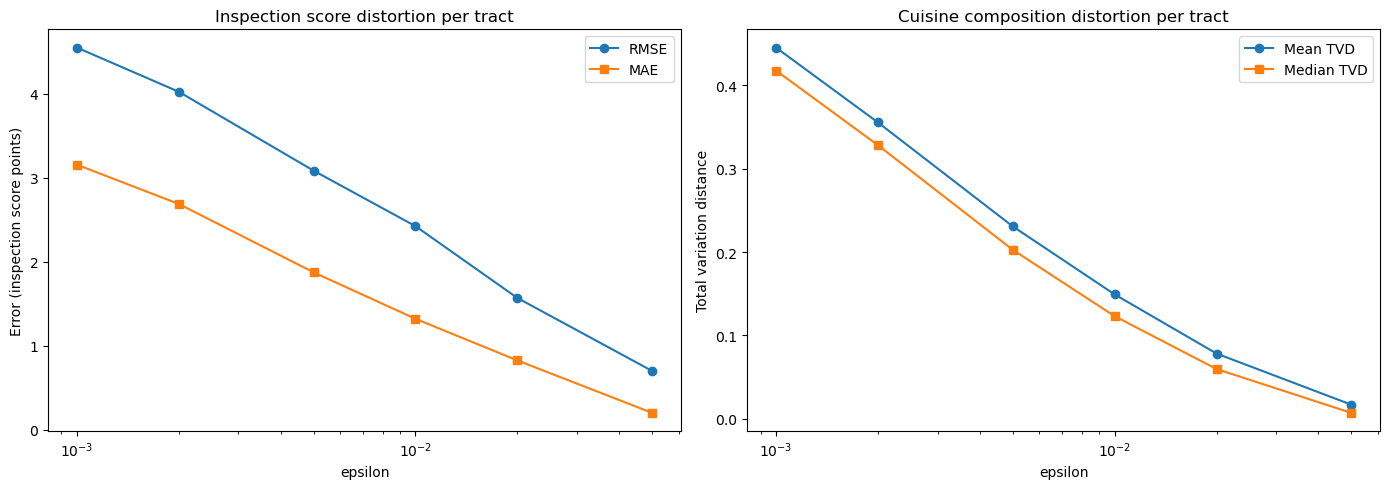

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(utility_score_df['epsilon'], utility_score_df['rmse'], marker='o', label='RMSE')
ax.plot(utility_score_df['epsilon'], utility_score_df['mae'], marker='s', label='MAE')
ax.set_xscale('log')
ax.set_xlabel('epsilon')
ax.set_ylabel('Error (inspection score points)')
ax.set_title('Inspection score distortion per tract')
ax.legend()

ax = axes[1]
ax.plot(utility_cuisine_df['epsilon'], utility_cuisine_df['tvd_mean'], marker='o', label='Mean TVD')
ax.plot(utility_cuisine_df['epsilon'], utility_cuisine_df['tvd_median'], marker='s', label='Median TVD')
ax.set_xscale('log')
ax.set_xlabel('epsilon')
ax.set_ylabel('Total variation distance')
ax.set_title('Cuisine composition distortion per tract')
ax.legend()

plt.tight_layout(); plt.show()

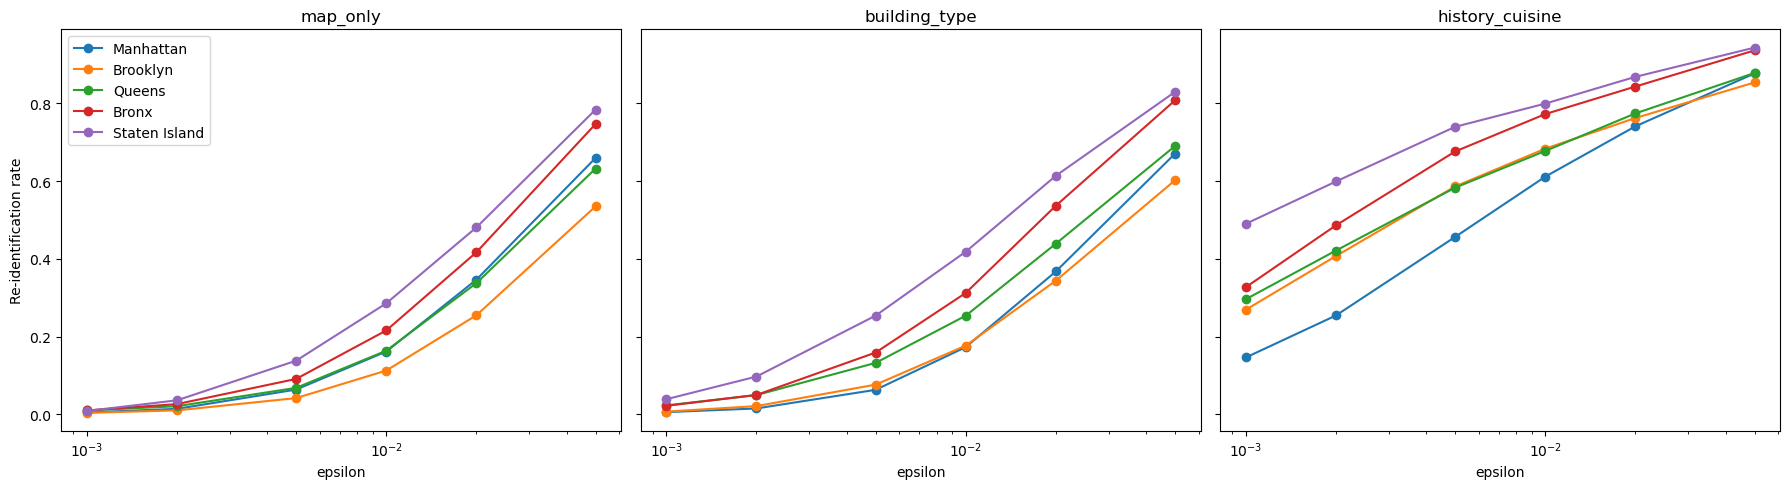

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, name in zip(axes, ['map_only', 'building_type', 'history_cuisine']):
    sub = borough_df[borough_df['prior'] == name]
    for borough in ['Manhattan', 'Brooklyn', 'Queens', 'Bronx', 'Staten Island']:
        b = sub[sub['borough'] == borough].sort_values('epsilon')
        ax.plot(b['epsilon'], b['reid_rate'], marker='o', label=borough)
    ax.set_xscale('log')
    ax.set_xlabel('epsilon')
    ax.set_title(name)
axes[0].set_ylabel('Re-identification rate')
axes[0].legend()
plt.tight_layout(); plt.show()

In [28]:
print('=' * 80)
print('1. SINGLE-QUERY RE-IDENTIFICATION RATE')
print('=' * 80)
for group in ['all', 'continuing', 'new']:
    print(f'\n--- {group} ---')
    print(prior_single[prior_single['group'] == group]
          .pivot(index='epsilon', columns='prior', values='reid_rate').round(4).to_string())

print('\n' + '=' * 80)
print('2. MULTI-RECORD (eps=0.01, all restaurants): one record (average) / all linked records')
print('=' * 80)
m01 = prior_multi[(prior_multi['epsilon'] == 0.01) & (prior_multi['group'] == 'all') & (prior_multi['grouping'] == 'n_bucket')]
print(m01.pivot(index='n_linked', columns='prior', values='reid_one_record_avg').round(4).to_string())
print(m01.pivot(index='n_linked', columns='prior', values='reid_rate').round(4).to_string())

print('\n' + '=' * 80)
print('3. UTILITY LOSS')
print('=' * 80)
print('Inspection score distortion:')
print(utility_score_df.to_string(index=False))
print('\nCuisine composition distortion:')
print(utility_cuisine_df.to_string(index=False))
print('\nTract coverage:')
print(utility_coverage_df.to_string(index=False))

print('\n' + '=' * 80)
print('4. BOROUGH (eps=0.01)')
print('=' * 80)
print(borough_summary.round(3).to_string(index=False))

1. SINGLE-QUERY RE-IDENTIFICATION RATE

--- all ---
prior    building_type  building_type_cuisine  control_units  control_year  everything  history_any  history_cuisine  map_only
epsilon                                                                                                                       
0.001           0.0126                 0.0128         0.0063        0.0054      0.2424       0.0383           0.2421    0.0062
0.002           0.0308                 0.0314         0.0181        0.0147      0.3667       0.0856           0.3670    0.0164
0.005           0.0984                 0.1003         0.0695        0.0610      0.5515       0.2185           0.5503    0.0640
0.010           0.2146                 0.2170         0.1650        0.1551      0.6738       0.3757           0.6673    0.1586
0.020           0.4030                 0.4045         0.3312        0.3284      0.7797       0.5617           0.7684    0.3319
0.050           0.6764                 0.6772         0.611

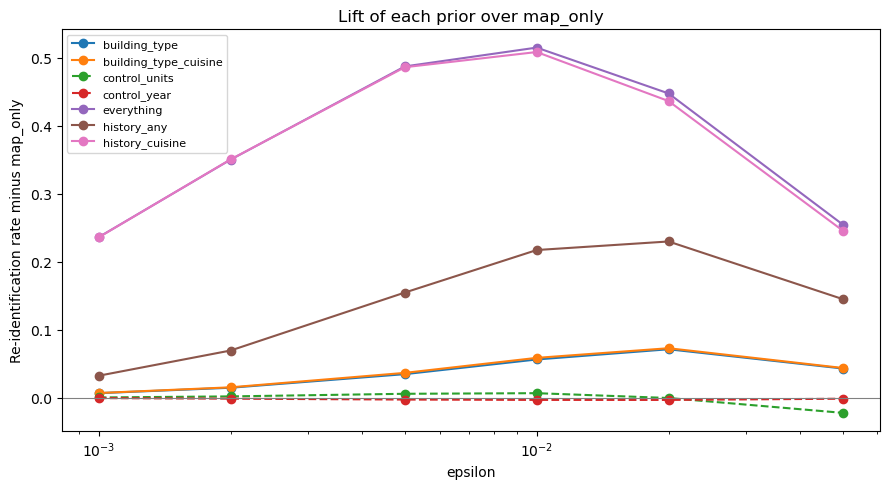

prior    building_type  building_type_cuisine  control_units  control_year  \
epsilon                                                                      
0.001           0.0064                 0.0066         0.0001       -0.0008   
0.002           0.0144                 0.0150         0.0016       -0.0017   
0.005           0.0344                 0.0363         0.0055       -0.0030   
0.010           0.0560                 0.0584         0.0064       -0.0035   
0.020           0.0711                 0.0726        -0.0007       -0.0036   
0.050           0.0427                 0.0435        -0.0226       -0.0018   

prior    everything  history_any  history_cuisine  
epsilon                                            
0.001        0.2361       0.0321           0.2359  
0.002        0.3503       0.0692           0.3505  
0.005        0.4875       0.1546           0.4863  
0.010        0.5152       0.2171           0.5087  
0.020        0.4477       0.2297           0.4365  
0.050      

In [29]:
reid_table = single_all.pivot(index='epsilon', columns='prior', values='reid_rate')
abs_lift = reid_table.sub(reid_table['map_only'], axis=0).drop(columns='map_only')

fig, ax = plt.subplots(figsize=(9, 5))
for name in abs_lift.columns:
    ax.plot(abs_lift.index, abs_lift[name], marker='o', label=name,
            linestyle='--' if name.startswith('control') else '-')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_xscale('log')
ax.set_xlabel('epsilon')
ax.set_ylabel('Re-identification rate minus map_only')
ax.set_title('Lift of each prior over map_only')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(abs_lift.round(4))

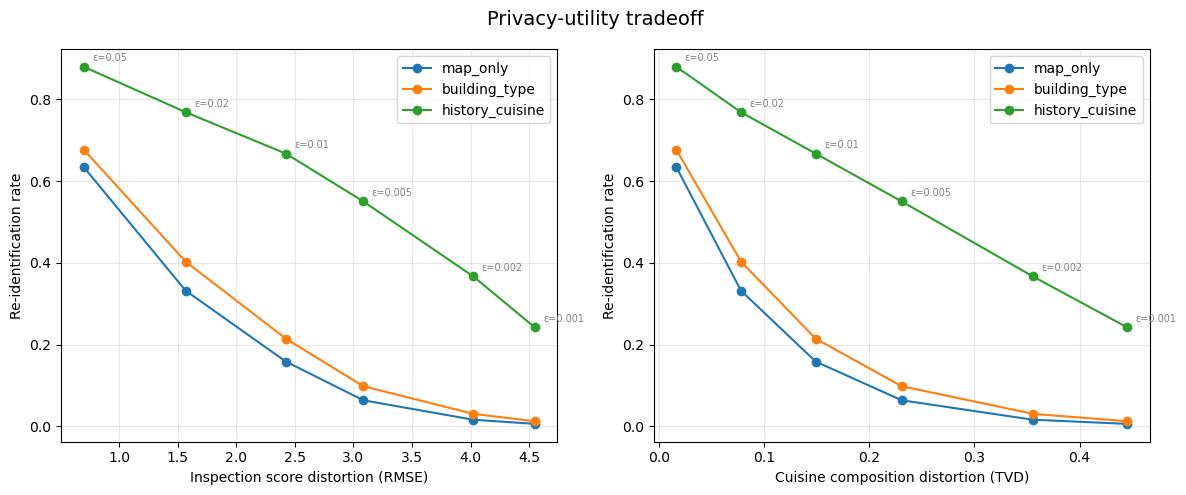

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
util_score = utility_score_df.set_index('epsilon')
util_cuisine = utility_cuisine_df.set_index('epsilon')

for ax, (util, col, label) in zip(axes, [(util_score, 'rmse', 'Inspection score distortion (RMSE)'),
                                         (util_cuisine, 'tvd_mean', 'Cuisine composition distortion (TVD)')]):
    for name in ['map_only', 'building_type', 'history_cuisine']:
        s = single_all[single_all['prior'] == name].sort_values('epsilon')
        x = util.loc[s['epsilon'], col].values
        ax.plot(x, s['reid_rate'].values, marker='o', label=name)
        if name == 'history_cuisine':
            for e, xi, yi in zip(s['epsilon'], x, s['reid_rate']):
                ax.annotate(f'ε={e}', (xi, yi), textcoords='offset points', xytext=(6, 4), fontsize=7, color='gray')
    ax.set_xlabel(label)
    ax.set_ylabel('Re-identification rate')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Privacy-utility tradeoff', fontsize=14)
plt.tight_layout()
plt.show()

## 9. Export results

In [31]:
from datetime import date

OUT = Path('results'); OUT.mkdir(exist_ok=True)

prior_single.to_csv(OUT / 'single_query.csv', index=False)
prior_multi.to_csv(OUT / 'multi_record.csv', index=False)
borough_df.to_csv(OUT / 'borough.csv', index=False)
borough_summary.to_csv(OUT / 'borough_density.csv', index=False)
spacing_cells.to_csv(OUT / 'spacing_by_borough.csv', index=False)
spacing_std.to_csv(OUT / 'spacing_standardized.csv', index=False)
pd.DataFrame(share_rows).to_csv(OUT / 'prior_shares.csv', index=False)
(abs_lift.reset_index()
 .melt(id_vars='epsilon', var_name='prior', value_name='abs_lift_over_map_only')
 .to_csv(OUT / 'prior_lift.csv', index=False))
utility_score_df.to_csv(OUT / 'utility_score.csv', index=False)
utility_cuisine_df.to_csv(OUT / 'utility_cuisine.csv', index=False)
utility_coverage_df.to_csv(OUT / 'utility_coverage.csv', index=False)
tract_util.to_csv(OUT / 'utility_by_tract.csv', index=False)
boro_util.to_csv(OUT / 'utility_by_borough.csv', index=False)
std_util.to_csv(OUT / 'utility_standardized_by_borough.csv', index=False)
nb_std.to_csv(OUT / 'utility_neighbor_standardized.csv', index=False)

pd.Series({
    'run_date': date.today().isoformat(),
    'train_window': f'{TRAIN_START} to {TEST_START} (exclusive)',
    'test_window': f'{TEST_START} to {TEST_END} (exclusive)',
    'pluto_lots': len(ref_df),
    'train_visits': len(train_visits), 'train_restaurants': train_visits['camis'].nunique(),
    'train_joined_to_pluto': len(train_merged),
    'test_visits': len(test), 'test_restaurants': test['camis'].nunique(),
    'test_visits_continuing': int(test_continuing.sum()),
    'test_restaurants_2plus': int((multi_counts >= 2).sum()),
    'test_restaurants_3plus': int((multi_counts >= 3).sum()),
    'multi_record_restaurants_2_to_8': n_rest,
    'median_geocode_to_lot_ft': round(float(np.median(offset))),
    'census_tracts': len(tracts),
}).rename_axis('quantity').rename('value').to_csv(OUT / 'data_summary.csv')

print('Wrote:', sorted(f.name for f in OUT.glob('*.csv')))

Wrote: ['borough.csv', 'borough_density.csv', 'data_summary.csv', 'multi_record.csv', 'prior_landuse_by_cuisine.csv', 'prior_lift.csv', 'prior_shares.csv', 'single_query.csv', 'spacing_by_borough.csv', 'spacing_standardized.csv', 'utility_by_borough.csv', 'utility_by_tract.csv', 'utility_coverage.csv', 'utility_cuisine.csv', 'utility_neighbor_standardized.csv', 'utility_score.csv', 'utility_standardized_by_borough.csv']
